# Train a small PyTorch MLP

**Goal:** Define the model, training loop, validation and reproducibility settings.
Can a neural network model interactions between mutations (epistasis) and predict GB1 fitness better than additive Ridge regression?

In [1]:
import torch
import torch.nn as nn

print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

data_path = Path("../data/raw/four_mutations_full_data.csv.zip")

df = pd.read_csv(data_path)
df_model = df[df["keep"] == True].copy()

#define training and test sets
train_df = df_model[df_model["sampled"] == "train"].copy()
test_df = df_model[df_model["sampled"] == "test"].copy()

print("Training:", len(train_df))
print("Testing:", len(test_df))

C:\Users\mw645\AppData\Local\Temp\ipykernel_16664\3817725342.py:7: DtypeWarning: Columns (8: one_vs_rest_validation, 10: two_vs_rest_validation, 12: three_vs_rest_validation) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_path)


Training: 6988
Testing: 1745


In [3]:
#reuse one-hot encoding 
amino_acids = "ACDEFGHIKLMNPQRSTVWY"

def one_hot_encode(variant):
    encoding = np.zeros((4, 20))

    for position, amino_acid in enumerate(variant):
        aa_index = amino_acids.index(amino_acid)
        encoding[position, aa_index] = 1

    return encoding.flatten()

X_train = np.stack(train_df["Variants"].apply(one_hot_encode))
X_test = np.stack(test_df["Variants"].apply(one_hot_encode))

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

Training shape: (6988, 80)
Test shape: (1745, 80)


In [4]:
#convert data into PyTorch tensors
y_train = train_df["Fitness"].to_numpy()
y_test = test_df["Fitness"].to_numpy()

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

print("Inputs:", X_train_tensor.shape)
print("Targets:", y_train_tensor.shape)

Inputs: torch.Size([6988, 80])
Targets: torch.Size([6988])


In [ ]:
#build the network (80 inputs, 32 neurons, one output - 2 linear layers and one ReLU)
#ReLU introduces nonlinerity, replacing negative values with 0 
model = nn.Sequential(
    nn.Linear(80, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)

print(model)

Sequential(
  (0): Linear(in_features=80, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=1, bias=True)
)


In [6]:
#define the loss function and optimiser
loss_fn = nn.MSELoss()
#mean squared error loss

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
#lr = learning rate

print("Loss function and optimiser ready!")


Loss function and optimiser ready!


In [ ]:
#write the training loop - jsut training data here
epochs = 100 #epoch is a complete pass through the training data (100 passes)
loss_history = []

for epoch in range(epochs):
    model.train()

    predictions = model(X_train_tensor)
    loss = loss_fn(predictions.squeeze(1), y_train_tensor) #loss function calc how far predicitons are from measured values - squeeze matches target shape
    optimizer.zero_grad() #clears gradients from previous pass
    loss.backward() # calculates how each weight contributed to error using backpropagation 
    optimizer.step() # Adam adjusts weights to try to reduce the error.

    loss_history.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1}: Loss = {loss.item():.4f}")

#biologically the network is learning the relationships between AA combinations and experimentally measured GB1 binding fitness

Epoch 10: Loss = 2.0703
Epoch 20: Loss = 1.8639
Epoch 30: Loss = 1.6654
Epoch 40: Loss = 1.4798
Epoch 50: Loss = 1.3171
Epoch 60: Loss = 1.1835
Epoch 70: Loss = 1.0777
Epoch 80: Loss = 0.9929
Epoch 90: Loss = 0.9227
Epoch 100: Loss = 0.8653


Training loss decreased from 2.0703 to 0.8653 in 100 epochs. Model is getting better at predicting fitness of training variants as it adjusts weights. Now evaluate neural network.

In [8]:
from sklearn.metrics import mean_squared_error
from scipy.stats import spearmanr

model.eval()

with torch.no_grad():
    predictions = model(X_test_tensor)
    y_pred_nn = predictions.squeeze(1).numpy()

rmse_nn = np.sqrt(mean_squared_error(y_test, y_pred_nn))
spearman_nn = spearmanr(y_test, y_pred_nn).statistic

print("Neural network RMSE:", round(rmse_nn, 3))
print("Neural network Spearman:", round(spearman_nn, 3))

Neural network RMSE: 0.922
Neural network Spearman: 0.79


Neural network hasn't clearly beaten the Ridge regression (RMSE = 0.855 and Spearman = 0.788)

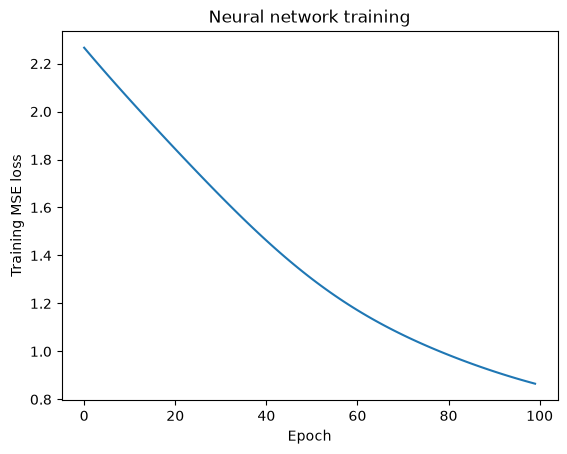

In [9]:
#plot trainig loss
import matplotlib.pyplot as plt

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Training MSE loss")
plt.title("Neural network training")
plt.show()

In [ ]:
#create validation set - validation to prevent overfitting
#divide the initial 6988 variants into 5590 training and 1398 validation 
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

print("Training:", len(X_fit))
print("Validation:", len(X_val))

Training: 5590
Validation: 1398


In [ ]:
#convert new sets into new tensors
X_fit_tensor = torch.tensor(X_fit, dtype=torch.float32)
y_fit_tensor = torch.tensor(y_fit, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)

print("Training inputs:", X_fit_tensor.shape)
print("Validation inputs:", X_val_tensor.shape)

Training inputs: torch.Size([5590, 80])
Validation inputs: torch.Size([1398, 80])


In [12]:
#reset neural network
torch.manual_seed(42)#makes the random initial weights reproducible 

model_val = nn.Sequential(
    nn.Linear(80, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)
#above creates a new network with the same architecture as original
loss_fn_val = nn.MSELoss() # loss function

optimizer_val = torch.optim.Adam(
    model_val.parameters(),
    lr=0.001
) # adjust new network weights during training

print(model_val)

Sequential(
  (0): Linear(in_features=80, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=1, bias=True)
)


In [14]:
#train with validation 
epochs = 300

train_losses = []
val_losses = []

for epoch in range(epochs):
    # Train the network
    model_val.train()

    predictions = model_val(X_fit_tensor)
    train_loss = loss_fn_val(predictions.squeeze(1), y_fit_tensor)

    optimizer_val.zero_grad()
    train_loss.backward()
    optimizer_val.step()

    # Evaluate on validation data
    model_val.eval()

    with torch.no_grad():
        val_predictions = model_val(X_val_tensor)
        val_loss = loss_fn_val(
            val_predictions.squeeze(1), y_val_tensor
        )

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Train = {train_loss.item():.4f}, "
            f"Validation = {val_loss.item():.4f}"
        )

Epoch 50: Train = 0.5571, Validation = 0.5428
Epoch 100: Train = 0.5189, Validation = 0.5079
Epoch 150: Train = 0.4771, Validation = 0.4697
Epoch 200: Train = 0.4349, Validation = 0.4309
Epoch 250: Train = 0.3952, Validation = 0.3949
Epoch 300: Train = 0.3598, Validation = 0.3624


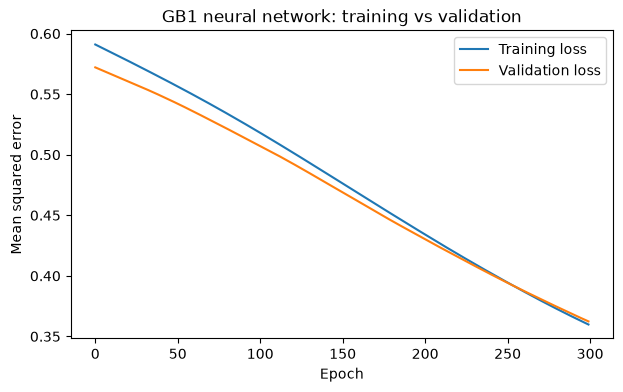

In [15]:
#visualise both curves
plt.figure(figsize=(7, 4))

plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("GB1 neural network: training vs validation")
plt.legend()
plt.show()

6988 variants avaliable for training - 5,590 training, 1398 validation.
For the training variants, the network sees their sequences and measured fitness values, calculates errors, and changes its weights to reduce those errors.
For the validation variants, the weights are not changed.
Here, both errors are still falling, so overfitting is not really a problem.

In [ ]:
#epoch of lowest validation error observed
print("Lowest validation loss:", round(min(val_losses), 4))
print("Best epoch:", np.argmin(val_losses) + 1)

Lowest validation loss: 0.3624
Best epoch: 300


In [18]:
#save current model weights incase things get worse
import copy

best_val_loss = min(val_losses) #remembers lowest validation loss
best_epoch = 300 #when this was achieved
best_model_weights = copy.deepcopy(model_val.state_dict()) #independent copy of the network's weights at epoch 300.

In [ ]:
#train for 200 more epochs - trying to work out how many epochs give us the best validation performance.
for epoch in range(301, 501):
    model_val.train()

    predictions = model_val(X_fit_tensor)
    train_loss = loss_fn_val(predictions.squeeze(1), y_fit_tensor)

    optimizer_val.zero_grad()
    train_loss.backward()
    optimizer_val.step()

    model_val.eval()
    with torch.no_grad():
        val_predictions = model_val(X_val_tensor)
        val_loss = loss_fn_val(
            val_predictions.squeeze(1), y_val_tensor
        )

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()
        best_epoch = epoch
        best_model_weights = copy.deepcopy(model_val.state_dict())

    if epoch % 50 == 0:
        print(f"Epoch {epoch}: Validation loss = {val_loss.item():.4f}")

print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))

Epoch 350: Validation loss = 0.3360
Epoch 400: Validation loss = 0.3154
Epoch 450: Validation loss = 0.3002
Epoch 500: Validation loss = 0.2877
Best epoch: 500
Best validation loss: 0.2877


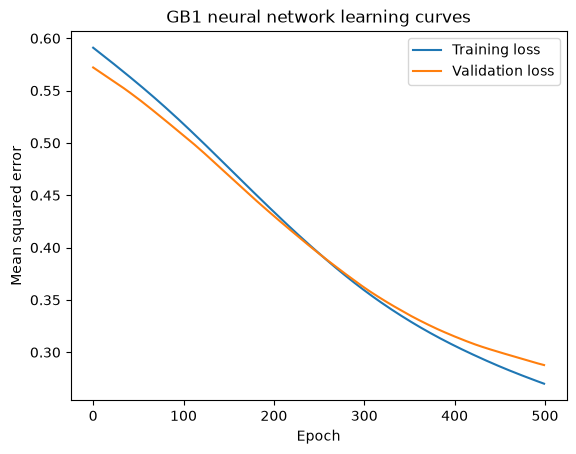

In [20]:
#update graph
plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("GB1 neural network learning curves")
plt.legend()
plt.show()

In [21]:
#up to 700 now
for epoch in range(501, 701):
    model_val.train()

    predictions = model_val(X_fit_tensor)
    train_loss = loss_fn_val(predictions.squeeze(1), y_fit_tensor)

    optimizer_val.zero_grad()
    train_loss.backward()
    optimizer_val.step()

    model_val.eval()
    with torch.no_grad():
        val_predictions = model_val(X_val_tensor)
        val_loss = loss_fn_val(
            val_predictions.squeeze(1), y_val_tensor
        )

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()
        best_epoch = epoch
        best_model_weights = copy.deepcopy(model_val.state_dict())

    if epoch % 50 == 0:
        print(f"Epoch {epoch}: Validation loss = {val_loss.item():.4f}")

print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))

Epoch 550: Validation loss = 0.2774
Epoch 600: Validation loss = 0.2686
Epoch 650: Validation loss = 0.2616
Epoch 700: Validation loss = 0.2550
Best epoch: 700
Best validation loss: 0.255


We'll continue training from epoch 700, but stop if validation doesn't improve for 100 consecutve epochs

In [22]:
patience = 100
epochs_without_improvement = 0

for epoch in range(701, 2001):
    model_val.train()

    predictions = model_val(X_fit_tensor)
    train_loss = loss_fn_val(predictions.squeeze(1), y_fit_tensor)

    optimizer_val.zero_grad()
    train_loss.backward()
    optimizer_val.step()

    model_val.eval()
    with torch.no_grad():
        val_predictions = model_val(X_val_tensor)
        val_loss = loss_fn_val(
            val_predictions.squeeze(1), y_val_tensor
        )

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()
        best_epoch = epoch
        best_model_weights = copy.deepcopy(model_val.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch % 100 == 0:
        print(f"Epoch {epoch}: Validation loss = {val_loss.item():.4f}")

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch}")
        break

print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))

Epoch 800: Validation loss = 0.2413
Epoch 900: Validation loss = 0.2291
Epoch 1000: Validation loss = 0.2199
Epoch 1100: Validation loss = 0.2137
Epoch 1200: Validation loss = 0.2072
Epoch 1300: Validation loss = 0.2027
Epoch 1400: Validation loss = 0.2005
Epoch 1500: Validation loss = 0.1977
Epoch 1600: Validation loss = 0.1968
Epoch 1700: Validation loss = 0.1964
Epoch 1800: Validation loss = 0.1959
Early stopping at epoch 1894
Best epoch: 1794
Best validation loss: 0.1959


In [23]:
#restore weights from 1794
model_val.load_state_dict(best_model_weights)

print("Restored model from epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))

Restored model from epoch: 1794
Best validation loss: 0.1959


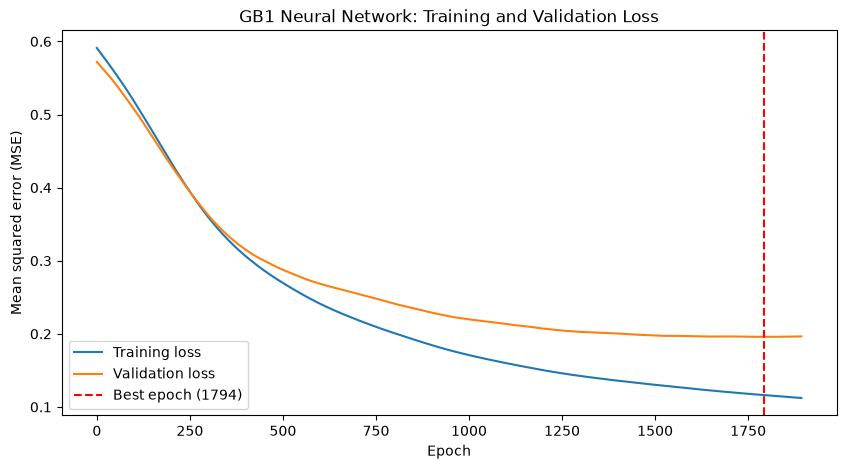

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")

plt.axvline(
    best_epoch - 1,
    color="red",
    linestyle="--",
    label=f"Best epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Mean squared error (MSE)")
plt.title("GB1 Neural Network: Training and Validation Loss")
plt.legend()
plt.show()

From validation experiment, learned that approx. 1794 epochs in this context give the lowest validation loss.
Now want to train final neural network suing all 6,988 training variants.

In [26]:
#create fresh neural network with same architecture as model_val
#now going to train on all 6,988 variants vs 5,590 selected.
torch.manual_seed(42)

model_final = nn.Sequential(
    nn.Linear(80, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)

optimizer_final = torch.optim.Adam(
    model_final.parameters(),
    lr=0.001
)

In [27]:
#train model_final for 1,794 epochs
final_losses = []

for epoch in range(1794):
    model_final.train()

    predictions = model_final(X_train_tensor)
    loss = loss_fn_val(
        predictions.squeeze(1),
        y_train_tensor
    )

    optimizer_final.zero_grad()
    loss.backward()
    optimizer_final.step()

    final_losses.append(loss.item())

    if (epoch + 1) % 300 == 0:
        print(f"Epoch {epoch + 1}: Training loss = {loss.item():.4f}")

print("Final training loss:", round(final_losses[-1], 4))

Epoch 300: Training loss = 0.5870
Epoch 600: Training loss = 0.3576
Epoch 900: Training loss = 0.2436
Epoch 1200: Training loss = 0.1913
Epoch 1500: Training loss = 0.1573
Final training loss: 0.1363


In [28]:
#evaluate
model_final.eval()

with torch.no_grad():
    test_predictions = model_final(X_test_tensor).squeeze(1).numpy()

from sklearn.metrics import mean_squared_error
from scipy.stats import spearmanr

final_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
final_spearman = spearmanr(y_test, test_predictions).statistic

print("Final neural network RMSE:", round(final_rmse, 3))
print("Final neural network Spearman:", round(final_spearman, 3))

Final neural network RMSE: 0.463
Final neural network Spearman: 0.91


Original Ridge regression achieved RMSE 0.855 and Spearman 0.788
Here RMSE = 0.463 and Spearman 0.91 - improvement!


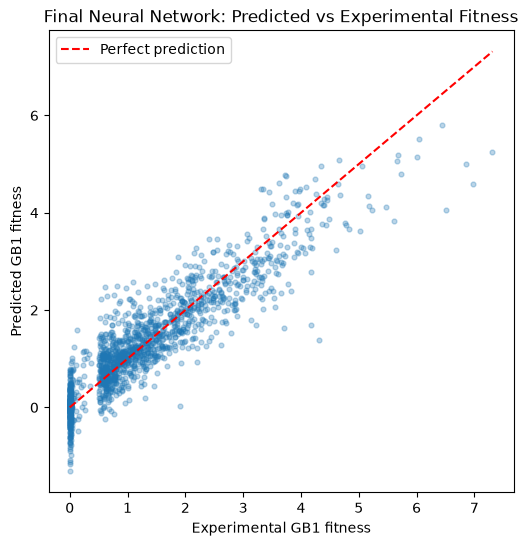

In [29]:
#visualise
plt.figure(figsize=(6, 6))

plt.scatter(y_test, test_predictions, alpha=0.3, s=12)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Experimental GB1 fitness")
plt.ylabel("Predicted GB1 fitness")
plt.title("Final Neural Network: Predicted vs Experimental Fitness")
plt.legend()
plt.show()

High fitness variants tend to be underpredicted and there's a large cluster at experimental fitness near 0.
Some values are predicted less than 0 as network's final layer has no restriction on outputs.